In [1]:
import cv2
import numpy as np
import os
import matplotlib.pyplot as plt
import random
from pathlib import Path

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def detectar_tablero_y_casillas(img, debug=False):
    """
    Detecta SOLO el tablero de ajedrez (8x8 casillas) encontrando sus 4 esquinas.
    Descarta números, letras y espacios externos.
    
    Args:
        img: imagen en formato RGB
        debug: si True, muestra imágenes de depuración
    
    Returns:
        casillas: lista de imágenes de casillas
        coords: coordenadas (x1, y1, x2, y2) del tablero
    """
    
    # Convertir a escala de grises
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    
    # 1. Aplicar CLAHE para mejorar contraste
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))
    gray = clahe.apply(gray)
    
    # 2. Aplicar blur para reducir ruido
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)
    
    # 3. Detectar bordes con Canny
    edges = cv2.Canny(blurred, 30, 100)
    
    # 4. Dilatar bordes para conectar líneas
    kernel = np.ones((3, 3), np.uint8)
    edges = cv2.dilate(edges, kernel, iterations=2)
    edges = cv2.erode(edges, kernel, iterations=1)
    
    # 5. Encontrar contornos
    contours, _ = cv2.findContours(edges, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    
    if debug:
        fig, axes = plt.subplots(2, 3, figsize=(15, 10))
        axes[0, 0].imshow(gray, cmap='gray')
        axes[0, 0].set_title('1. Escala de grises')
        axes[0, 1].imshow(blurred, cmap='gray')
        axes[0, 1].set_title('2. Blur')
        axes[0, 2].imshow(edges, cmap='gray')
        axes[0, 2].set_title('3. Bordes')
    
    # 6. Filtrar contornos para encontrar el tablero
    height, width = img.shape[:2]
    area_min = (width * height) * 0.15  # Mínimo 15% de la imagen
    area_max = (width * height) * 0.9   # Máximo 90% de la imagen
    
    mejores_candidatos = []
    
    for contour in contours:
        area = cv2.contourArea(contour)
        if area_min < area < area_max:
            # Aproximar polígono
            peri = cv2.arcLength(contour, True)
            approx = cv2.approxPolyDP(contour, 0.02 * peri, True)
            
            # Buscar cuadriláteros
            if len(approx) == 4:
                # Calcular relación de aspecto
                x, y, w, h = cv2.boundingRect(approx)
                aspect_ratio = w / h
                
                # El tablero debe ser casi cuadrado (ratio entre 0.8 y 1.2)
                if 0.7 < aspect_ratio < 1.3:
                    # Calcular convexidad
                    hull = cv2.convexHull(contour)
                    hull_area = cv2.contourArea(hull)
                    convexity = area / hull_area if hull_area > 0 else 0
                    
                    # El tablero debe ser convexo
                    if convexity > 0.85:
                        mejores_candidatos.append((area, approx, (x, y, w, h)))
    
    if debug:
        # Dibujar candidatos
        img_candidatos = img.copy()
        for _, approx, (x, y, w, h) in mejores_candidatos:
            cv2.drawContours(img_candidatos, [approx], -1, (0, 255, 0), 2)
        axes[1, 0].imshow(img_candidatos)
        axes[1, 0].set_title(f'4. Candidatos ({len(mejores_candidatos)})')
    
    # 7. Ordenar candidatos por área (mayor primero)
    mejores_candidatos.sort(key=lambda x: x[0], reverse=True)
    
    if mejores_candidatos:
        # Tomar el mejor candidato
        _, tablero_contour, (x, y, w, h) = mejores_candidatos[0]
        
        if debug:
            img_rect = img.copy()
            cv2.drawContours(img_rect, [tablero_contour], -1, (0, 255, 0), 3)
            cv2.rectangle(img_rect, (x, y), (x+w, y+h), (255, 0, 0), 3)
            axes[1, 1].imshow(img_rect)
            axes[1, 1].set_title('5. Tablero detectado')
            
            # Mostrar el contorno aproximado
            img_approx = img.copy()
            cv2.drawContours(img_approx, [tablero_contour], -1, (0, 255, 0), 3)
            axes[1, 2].imshow(img_approx)
            axes[1, 2].set_title('6. Contorno final')
        
        # 8. Recortar el tablero
        tablero = img[y:y+h, x:x+w]
        
        # 9. Dividir en 8x8 casillas
        h_cell = h // 8
        w_cell = w // 8
        
        casillas = []
        for i in range(8):
            for j in range(8):
                y1 = i * h_cell
                y2 = (i + 1) * h_cell
                x1 = j * w_cell
                x2 = (j + 1) * w_cell
                
                casilla = tablero[y1:y2, x1:x2]
                casillas.append(casilla)
        
        if debug:
            plt.tight_layout()
            plt.show()
        
        return casillas, (x, y, x+w, y+h)
    
    # 8. Si no se encontró un cuadrilátero, intentar con bounding rect del contorno más grande
    if contours:
        # Tomar el contorno más grande
        largest_contour = max(contours, key=cv2.contourArea)
        x, y, w, h = cv2.boundingRect(largest_contour)
        
        if debug:
            img_rect = img.copy()
            cv2.rectangle(img_rect, (x, y), (x+w, y+h), (0, 255, 0), 3)
            axes[1, 1].imshow(img_rect)
            axes[1, 1].set_title('5. Fallback: bounding rect')
            plt.tight_layout()
            plt.show()
        
        tablero = img[y:y+h, x:x+w]
        h_cell = h // 8
        w_cell = w // 8
        
        casillas = []
        for i in range(8):
            for j in range(8):
                y1 = i * h_cell
                y2 = (i + 1) * h_cell
                x1 = j * w_cell
                x2 = (j + 1) * w_cell
                casilla = tablero[y1:y2, x1:x2]
                casillas.append(casilla)
        
        return casillas, (x, y, x+w, y+h)
    
    # 9. Último recurso: asumir que el tablero está centrado
    if debug:
        plt.tight_layout()
        plt.show()
        print("No se detectó el tablero, usando valores por defecto")
    
    # Calcular un área central que probablemente contenga el tablero
    margen_x = width // 8
    margen_y = height // 8
    x = margen_x
    y = margen_y
    w = width - 2 * margen_x
    h = height - 2 * margen_y
    
    tablero = img[y:y+h, x:x+w]
    h_cell = h // 8
    w_cell = w // 8
    
    casillas = []
    for i in range(8):
        for j in range(8):
            y1 = i * h_cell
            y2 = (i + 1) * h_cell
            x1 = j * w_cell
            x2 = (j + 1) * w_cell
            casilla = tablero[y1:y2, x1:x2]
            casillas.append(casilla)
    
    return casillas, (x, y, x+w, y+h)

In [3]:
def seleccionar_tablero_manual_matplotlib(img_path):
    """
    Permite seleccionar manualmente las 4 esquinas del tablero usando matplotlib.
    No requiere ventanas de OpenCV.
    """
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    
    puntos = []
    
    def onclick(event):
        if event.xdata is not None and event.ydata is not None:
            x, y = int(event.xdata), int(event.ydata)
            puntos.append((x, y))
            print(f"Punto {len(puntos)} seleccionado: ({x}, {y})")
            
            # Dibujar el punto en la figura
            plt.plot(x, y, 'ro', markersize=10)
            plt.text(x+5, y-5, str(len(puntos)), color='red', fontsize=12, weight='bold')
            plt.draw()
            
            if len(puntos) == 4:
                print("\n¡Los 4 puntos han sido seleccionados!")
                plt.close()
    
    # Mostrar imagen y esperar clicks
    fig, ax = plt.subplots(figsize=(12, 10))
    ax.imshow(img)
    ax.set_title("Haz clic en las 4 esquinas del tablero en orden:\n1. Superior izquierda\n2. Superior derecha\n3. Inferior derecha\n4. Inferior izquierda")
    ax.axis('off')
    
    # Conectar evento de click
    cid = fig.canvas.mpl_connect('button_press_event', onclick)
    
    plt.show()
    
    if len(puntos) == 4:
        pts = np.array(puntos, dtype=np.float32)
        
        # Ordenar puntos correctamente
        # Ordenar por Y (arriba a abajo)
        pts_by_y = sorted(pts, key=lambda p: p[1])
        top_pts = sorted(pts_by_y[:2], key=lambda p: p[0])
        bottom_pts = sorted(pts_by_y[2:], key=lambda p: p[0])
        
        top_left = top_pts[0]
        top_right = top_pts[1]
        bottom_left = bottom_pts[0]
        bottom_right = bottom_pts[1]
        
        ordered_pts = np.array([top_left, top_right, bottom_right, bottom_left], dtype=np.float32)
        
        # Calcular dimensiones
        width = max(
            np.linalg.norm(ordered_pts[1] - ordered_pts[0]),
            np.linalg.norm(ordered_pts[2] - ordered_pts[3])
        )
        height = max(
            np.linalg.norm(ordered_pts[3] - ordered_pts[0]),
            np.linalg.norm(ordered_pts[2] - ordered_pts[1])
        )
        
        # Aplicar transformación de perspectiva
        dst_pts = np.array([[0, 0], [width-1, 0], 
                           [width-1, height-1], [0, height-1]], dtype=np.float32)
        M = cv2.getPerspectiveTransform(ordered_pts, dst_pts)
        rectified = cv2.warpPerspective(img, M, (int(width), int(height)))
        
        # Mostrar resultado
        fig, axes = plt.subplots(1, 2, figsize=(14, 6))
        axes[0].imshow(img)
        for p in puntos:
            axes[0].plot(p[0], p[1], 'ro', markersize=8)
        axes[0].set_title('Puntos seleccionados')
        axes[0].axis('off')
        
        axes[1].imshow(rectified)
        axes[1].set_title('Tablero rectificado')
        axes[1].axis('off')
        plt.show()
        
        return rectified, ordered_pts
    
    return None, None

In [4]:
def detectar_tablero_y_casillas_v2(img, debug=False):
    """
    Versión mejorada que no requiere GUI de OpenCV.
    Detecta el tablero encontrando el contorno cuadrado más grande.
    """
    
    # Convertir a escala de grises
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    
    # 1. Aplicar CLAHE para mejorar contraste
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))
    gray = clahe.apply(gray)
    
    # 2. Aplicar blur para reducir ruido
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)
    
    # 3. Detectar bordes con Canny
    edges = cv2.Canny(blurred, 30, 100)
    
    # 4. Dilatar bordes para conectar líneas
    kernel = np.ones((3, 3), np.uint8)
    edges = cv2.dilate(edges, kernel, iterations=2)
    
    # 5. Encontrar contornos
    contours, _ = cv2.findContours(edges, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    
    if debug:
        fig, axes = plt.subplots(2, 3, figsize=(15, 10))
        axes[0, 0].imshow(gray, cmap='gray')
        axes[0, 0].set_title('1. Escala de grises con CLAHE')
        axes[0, 1].imshow(blurred, cmap='gray')
        axes[0, 1].set_title('2. Blur')
        axes[0, 2].imshow(edges, cmap='gray')
        axes[0, 2].set_title('3. Bordes')
    
    # 6. Filtrar contornos para encontrar el tablero
    height, width = img.shape[:2]
    area_min = (width * height) * 0.15
    area_max = (width * height) * 0.9
    
    mejores_candidatos = []
    
    for contour in contours:
        area = cv2.contourArea(contour)
        if area_min < area < area_max:
            # Aproximar polígono
            peri = cv2.arcLength(contour, True)
            approx = cv2.approxPolyDP(contour, 0.02 * peri, True)
            
            # Buscar cuadriláteros
            if len(approx) == 4:
                x, y, w, h = cv2.boundingRect(approx)
                aspect_ratio = w / h
                
                # El tablero debe ser casi cuadrado
                if 0.7 < aspect_ratio < 1.3:
                    # Calcular convexidad
                    hull = cv2.convexHull(contour)
                    hull_area = cv2.contourArea(hull)
                    convexity = area / hull_area if hull_area > 0 else 0
                    
                    if convexity > 0.85:
                        mejores_candidatos.append((area, approx, (x, y, w, h)))
    
    if debug:
        # Dibujar candidatos
        img_candidatos = img.copy()
        for _, approx, (x, y, w, h) in mejores_candidatos:
            cv2.drawContours(img_candidatos, [approx], -1, (0, 255, 0), 2)
        axes[1, 0].imshow(img_candidatos)
        axes[1, 0].set_title(f'4. Candidatos ({len(mejores_candidatos)})')
    
    # 7. Ordenar candidatos por área
    mejores_candidatos.sort(key=lambda x: x[0], reverse=True)
    
    if mejores_candidatos:
        _, tablero_contour, (x, y, w, h) = mejores_candidatos[0]
        
        if debug:
            img_rect = img.copy()
            cv2.drawContours(img_rect, [tablero_contour], -1, (0, 255, 0), 3)
            cv2.rectangle(img_rect, (x, y), (x+w, y+h), (255, 0, 0), 3)
            axes[1, 1].imshow(img_rect)
            axes[1, 1].set_title('5. Tablero detectado')
            
            img_approx = img.copy()
            cv2.drawContours(img_approx, [tablero_contour], -1, (0, 255, 0), 3)
            axes[1, 2].imshow(img_approx)
            axes[1, 2].set_title('6. Contorno final')
        
        # Recortar el tablero
        tablero = img[y:y+h, x:x+w]
        
        # Dividir en 8x8 casillas
        h_cell = h // 8
        w_cell = w // 8
        
        casillas = []
        for i in range(8):
            for j in range(8):
                y1 = i * h_cell
                y2 = (i + 1) * h_cell
                x1 = j * w_cell
                x2 = (j + 1) * w_cell
                
                casilla = tablero[y1:y2, x1:x2]
                casillas.append(casilla)
        
        if debug:
            plt.tight_layout()
            plt.show()
        
        return casillas, (x, y, x+w, y+h)
    
    # 8. Si no se encontró, usar el bounding rect del contorno más grande
    if contours:
        largest_contour = max(contours, key=cv2.contourArea)
        x, y, w, h = cv2.boundingRect(largest_contour)
        
        if debug:
            img_rect = img.copy()
            cv2.rectangle(img_rect, (x, y), (x+w, y+h), (0, 255, 0), 3)
            axes[1, 1].imshow(img_rect)
            axes[1, 1].set_title('5. Fallback: bounding rect')
            plt.tight_layout()
            plt.show()
        
        tablero = img[y:y+h, x:x+w]
        h_cell = h // 8
        w_cell = w // 8
        
        casillas = []
        for i in range(8):
            for j in range(8):
                y1 = i * h_cell
                y2 = (i + 1) * h_cell
                x1 = j * w_cell
                x2 = (j + 1) * w_cell
                casilla = tablero[y1:y2, x1:x2]
                casillas.append(casilla)
        
        return casillas, (x, y, x+w, y+h)
    
    # 9. Último recurso: asumir que el tablero está centrado
    if debug:
        plt.tight_layout()
        plt.show()
        print("No se detectó el tablero, usando valores por defecto")
    
    margen_x = width // 10
    margen_y = height // 10
    x = margen_x
    y = margen_y
    w = width - 2 * margen_x
    h = height - 2 * margen_y
    
    tablero = img[y:y+h, x:x+w]
    h_cell = h // 8
    w_cell = w // 8
    
    casillas = []
    for i in range(8):
        for j in range(8):
            y1 = i * h_cell
            y2 = (i + 1) * h_cell
            x1 = j * w_cell
            x2 = (j + 1) * w_cell
            casilla = tablero[y1:y2, x1:x2]
            casillas.append(casilla)
    
    return casillas, (x, y, x+w, y+h)

In [5]:
# Función para calibrar manualmente las coordenadas del tablero (si la detección automática falla)
def calibrar_coordenadas_manual(img_path, debug=True):
    """
    Función para calibrar manualmente las coordenadas del tablero.
    Permite seleccionar puntos de referencia para mejorar la detección.
    """
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    height, width = img.shape[:2]
    
    # Detectar esquinas del tablero usando contornos
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    edges = cv2.Canny(gray, 50, 150)
    
    contours, _ = cv2.findContours(edges, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    
    if not contours:
        # Si no hay contornos, usar toda la imagen
        if debug:
            print("No se detectaron contornos, usando toda la imagen")
        return (0, 0, width, height), img
    
    # Encontrar el contorno más grande (probablemente el tablero)
    largest_contour = max(contours, key=cv2.contourArea)
    
    # Aproximar el contorno a un polígono
    peri = cv2.arcLength(largest_contour, True)
    approx = cv2.approxPolyDP(largest_contour, 0.02 * peri, True)
    
    if len(approx) >= 4:
        # Tomar los primeros 4 puntos para el cuadrilátero
        corners = approx[:4].reshape(4, 2).astype(np.float32)
        
        # Ordenar esquinas (superior-izquierda, superior-derecha, inferior-derecha, inferior-izquierda)
        corners_sorted = np.zeros((4, 2), dtype=np.float32)
        
        # Sumar coordenadas: la menor suma es la esquina superior izquierda
        sum_coords = corners.sum(axis=1)
        corners_sorted[0] = corners[np.argmin(sum_coords)]
        corners_sorted[2] = corners[np.argmax(sum_coords)]
        
        # Restar coordenadas: la menor diferencia es la esquina superior derecha
        diff_coords = np.diff(corners, axis=1)
        corners_sorted[1] = corners[np.argmin(diff_coords)]
        corners_sorted[3] = corners[np.argmax(diff_coords)]
        
        # Calcular dimensiones del tablero
        width_tablero = max(
            np.linalg.norm(corners_sorted[1] - corners_sorted[0]),
            np.linalg.norm(corners_sorted[2] - corners_sorted[3])
        )
        height_tablero = max(
            np.linalg.norm(corners_sorted[3] - corners_sorted[0]),
            np.linalg.norm(corners_sorted[2] - corners_sorted[1])
        )
        
        # Aplicar transformación de perspectiva para obtener un tablero rectificado
        dst_pts = np.array([[0, 0], [width_tablero-1, 0], 
                           [width_tablero-1, height_tablero-1], 
                           [0, height_tablero-1]], dtype=np.float32)
        M = cv2.getPerspectiveTransform(corners_sorted, dst_pts)
        rectified = cv2.warpPerspective(img, M, (int(width_tablero), int(height_tablero)))
        
        if debug:
            # Mostrar resultados de calibración
            fig, axes = plt.subplots(1, 3, figsize=(15, 5))
            axes[0].imshow(img)
            for corner in corners:
                axes[0].plot(corner[0], corner[1], 'ro', markersize=8)
            axes[0].set_title('Imagen original con esquinas detectadas')
            axes[0].axis('off')
            
            axes[1].imshow(rectified)
            axes[1].set_title('Tablero rectificado')
            axes[1].axis('off')
            
            # Mostrar líneas de división del tablero
            axes[2].imshow(rectified)
            h, w = rectified.shape[:2]
            for i in range(1, 8):
                axes[2].axhline(y=i * h // 8, color='red', linestyle='--', alpha=0.5)
                axes[2].axvline(x=i * w // 8, color='red', linestyle='--', alpha=0.5)
            axes[2].set_title('División en casillas')
            axes[2].axis('off')
            
            plt.tight_layout()
            plt.show()
        
        # Devolver coordenadas del tablero en la imagen original
        x1 = int(min(corners[:, 0]))
        y1 = int(min(corners[:, 1]))
        x2 = int(max(corners[:, 0]))
        y2 = int(max(corners[:, 1]))
        
        return (x1, y1, x2, y2), rectified
    
    # Si no se encontró un cuadrilátero, usar el bounding rect
    x, y, w, h = cv2.boundingRect(largest_contour)
    tablero = img[y:y+h, x:x+w]
    return (x, y, x+w, y+h), tablero

In [6]:
# Configuración de directorios
input_dir = "tablero_real"
output_dir = "dataset_casillas_auto"
os.makedirs(output_dir, exist_ok=True)

print(f"Directorio de entrada: {input_dir}")
print(f"Directorio de salida: {output_dir}")

# Verificar que existe el directorio de entrada
if not os.path.exists(input_dir):
    print(f"ERROR: El directorio {input_dir} no existe!")
    print("Por favor, crea el directorio y coloca las imágenes allí.")

Directorio de entrada: tablero_real
Directorio de salida: dataset_casillas_auto


Probando con imagen: D:\Dataset\Tablero Ajedrez\tablero_real\photo_1_2026-03-29_21-35-04.jpg


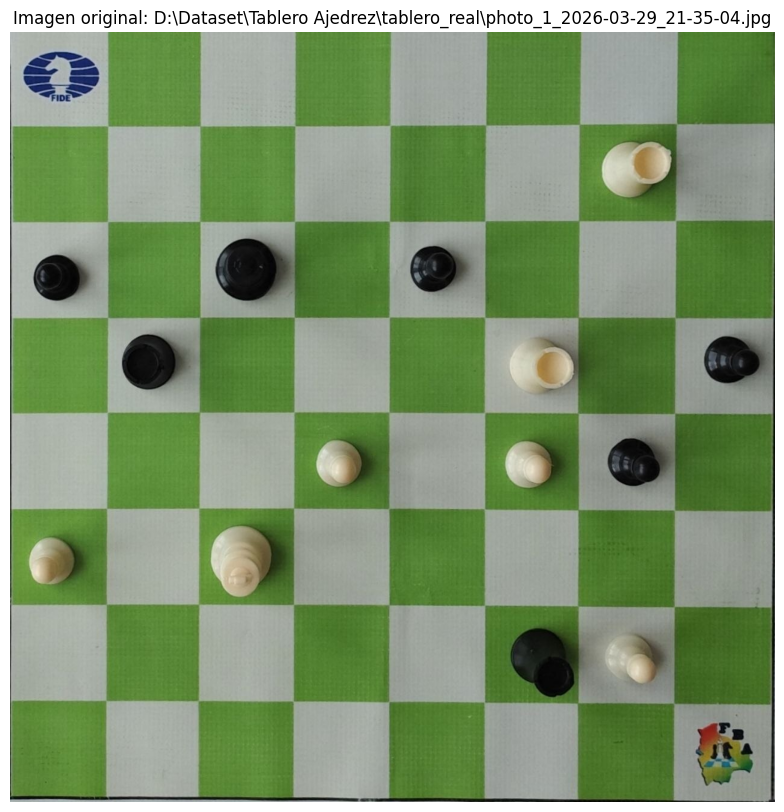


Detectando tablero automáticamente...


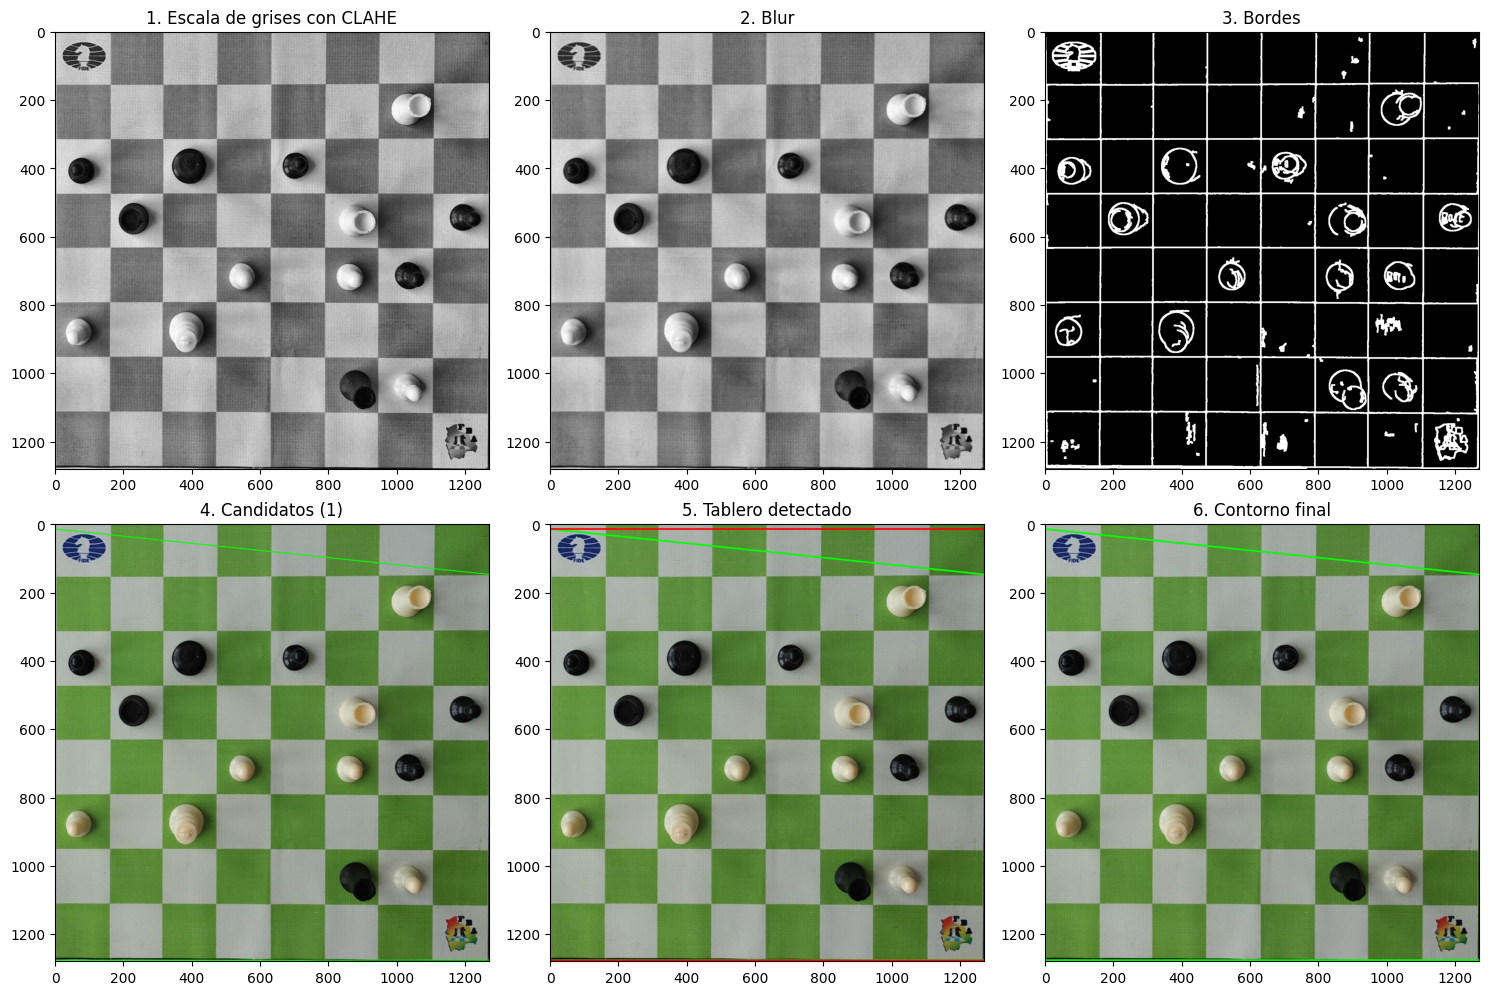


Tablero detectado en coordenadas: (0, 17, 1271, 1278)
Dimensiones del tablero: 1271 x 1261 pixeles
Se generaron 64 casillas


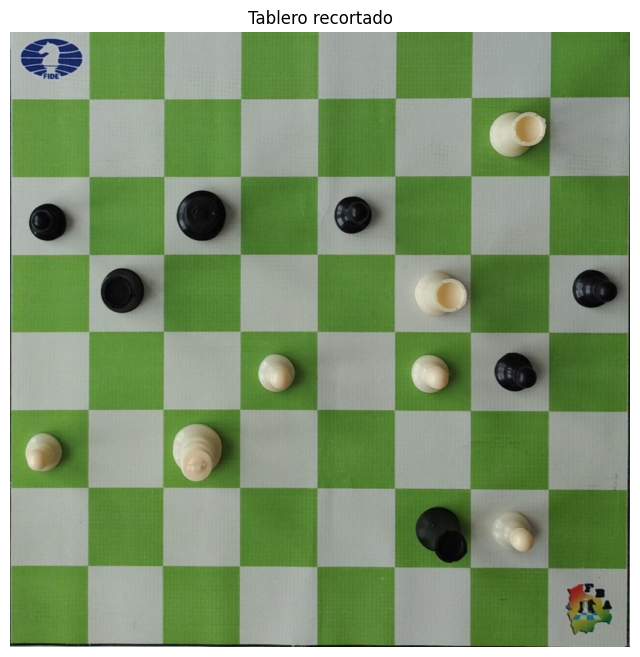

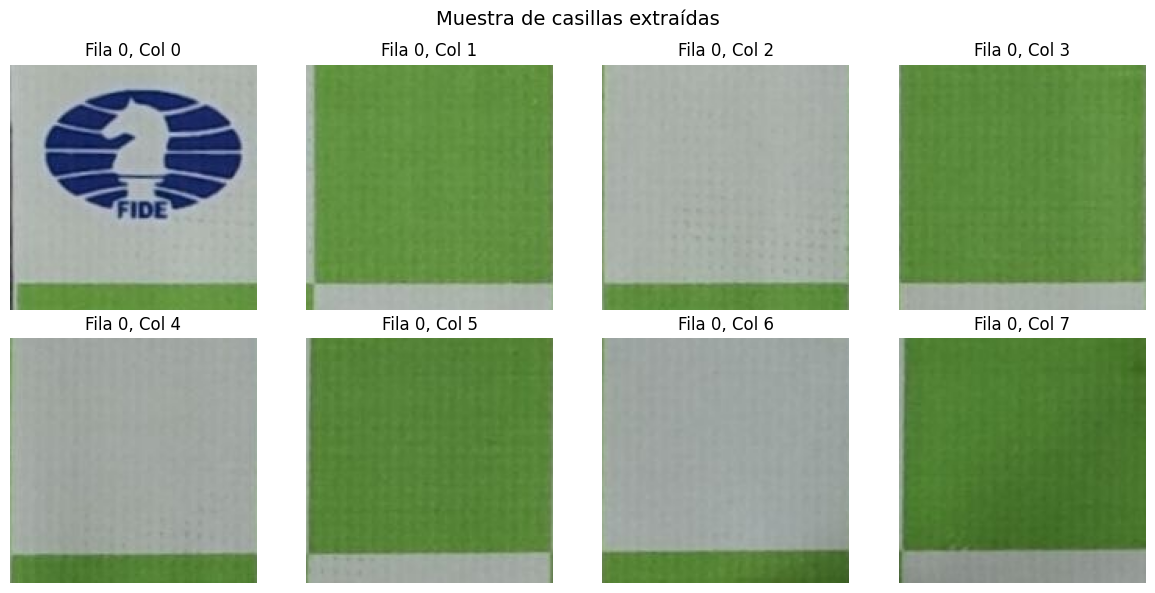


Coordenadas guardadas en coordenadas_detectadas.txt


In [7]:
# Probar con una imagen específica
imagen_prueba = "D:\\Dataset\\Tablero Ajedrez\\tablero_real\\photo_1_2026-03-29_21-35-04.jpg"
ruta_prueba = os.path.join(input_dir, imagen_prueba)

if os.path.exists(ruta_prueba):
    print(f"Probando con imagen: {imagen_prueba}")
    
    # Cargar imagen
    img = cv2.imread(ruta_prueba)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    
    # Mostrar imagen original
    plt.figure(figsize=(12, 10))
    plt.imshow(img)
    plt.title(f"Imagen original: {imagen_prueba}")
    plt.axis('off')
    plt.show()
    
    # Detectar tablero automáticamente con debug=True
    print("\nDetectando tablero automáticamente...")
    casillas, coords = detectar_tablero_y_casillas_v2(img, debug=True)
    
    print(f"\nTablero detectado en coordenadas: {coords}")
    print(f"Dimensiones del tablero: {coords[2]-coords[0]} x {coords[3]-coords[1]} pixeles")
    print(f"Se generaron {len(casillas)} casillas")
    
    if len(casillas) == 64:
        # Mostrar el tablero recortado
        tablero_recortado = img[coords[1]:coords[3], coords[0]:coords[2]]
        plt.figure(figsize=(8, 8))
        plt.imshow(tablero_recortado)
        plt.title("Tablero recortado")
        plt.axis('off')
        plt.show()
        
        # Mostrar algunas casillas
        fig, axes = plt.subplots(2, 4, figsize=(12, 6))
        for idx, ax in enumerate(axes.flat):
            if idx < min(8, len(casillas)):
                ax.imshow(casillas[idx])
                fila = idx // 8
                col = idx % 8
                ax.set_title(f"Fila {fila}, Col {col}")
            ax.axis('off')
        plt.suptitle("Muestra de casillas extraídas", fontsize=14)
        plt.tight_layout()
        plt.show()
        
        # Guardar coordenadas para usar después
        with open("coordenadas_detectadas.txt", "w") as f:
            f.write(f"x1={coords[0]}, y1={coords[1]}, x2={coords[2]}, y2={coords[3]}\n")
        print(f"\nCoordenadas guardadas en coordenadas_detectadas.txt")
        
    else:
        print(f"Error: No se generaron 64 casillas. Se obtuvieron {len(casillas)}")
        
else:
    print(f"ERROR: No se encontró la imagen {imagen_prueba}")

In [8]:
# Procesar todas las imágenes del directorio
total_casillas = 0
imagenes_procesadas = 0
imagenes_con_error = 0
errores = []

# Obtener lista de imágenes
imagenes = [f for f in os.listdir(input_dir) if f.endswith((".jpg", ".png", ".jpeg"))]
print(f"Total de imágenes encontradas: {len(imagenes)}")
print("Procesando imágenes...\n")

for idx, archivo in enumerate(imagenes, 1):
    ruta = os.path.join(input_dir, archivo)
    nombre_base = os.path.splitext(archivo)[0]
    
    print(f"[{idx}/{len(imagenes)}] Procesando: {archivo}")
    
    try:
        # Cargar imagen
        img = cv2.imread(ruta)
        if img is None:
            print(f"  ✗ No se pudo cargar la imagen")
            imagenes_con_error += 1
            errores.append(archivo)
            continue
        
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        
        # Detectar tablero y casillas
        casillas, coords = detectar_tablero_y_casillas(img, debug=False)
        
        # Guardar cada casilla
        for casilla_idx, casilla in enumerate(casillas):
            fila = casilla_idx // 8
            col = casilla_idx % 8
            nombre = f"{output_dir}/{nombre_base}_f{fila}_c{col}.png"
            cv2.imwrite(nombre, cv2.cvtColor(casilla, cv2.COLOR_RGB2BGR))
        
        total_casillas += len(casillas)
        imagenes_procesadas += 1
        print(f"  ✓ {len(casillas)} casillas guardadas en {output_dir}")
        
    except Exception as e:
        print(f"  ✗ Error procesando {archivo}: {e}")
        imagenes_con_error += 1
        errores.append(f"{archivo}: {str(e)}")
        
        # Intentar con calibración manual como fallback
        try:
            print(f"    Intentando calibración manual...")
            coords, rectified = calibrar_coordenadas_manual(ruta, debug=False)
            if rectified is not None:
                # Procesar el tablero rectificado
                h, w = rectified.shape[:2]
                h_cell = h // 8
                w_cell = w // 8
                
                for i in range(8):
                    for j in range(8):
                        y1 = i * h_cell
                        y2 = (i + 1) * h_cell
                        x1 = j * w_cell
                        x2 = (j + 1) * w_cell
                        
                        casilla = rectified[y1:y2, x1:x2]
                        nombre = f"{output_dir}/{nombre_base}_f{i}_c{j}.png"
                        cv2.imwrite(nombre, cv2.cvtColor(casilla, cv2.COLOR_RGB2BGR))
                        total_casillas += 1
                
                imagenes_procesadas += 1
                print(f"    ✓ Calibración manual exitosa: 64 casillas")
        except Exception as e2:
            print(f"    ✗ Calibración manual también falló: {e2}")

# Resumen final
print("\n" + "="*60)
print("RESUMEN DE PROCESAMIENTO")
print("="*60)
print(f"Imágenes procesadas exitosamente: {imagenes_procesadas}")
print(f"Imágenes con error: {imagenes_con_error}")
print(f"Total de casillas generadas: {total_casillas}")
print(f"Directorio de salida: {output_dir}")
print("="*60)

if errores:
    print("\nImágenes con error:")
    for error in errores:
        print(f"  - {error}")

Total de imágenes encontradas: 51
Procesando imágenes...

[1/51] Procesando: photo_10_2026-03-29_21-35-04.jpg
  ✓ 64 casillas guardadas en dataset_casillas_auto
[2/51] Procesando: photo_10_2026-04-12_19-35-01.jpg
  ✓ 64 casillas guardadas en dataset_casillas_auto
[3/51] Procesando: photo_11_2026-03-29_21-35-04.jpg
  ✓ 64 casillas guardadas en dataset_casillas_auto
[4/51] Procesando: photo_11_2026-04-12_19-35-01.jpg
  ✓ 64 casillas guardadas en dataset_casillas_auto
[5/51] Procesando: photo_12_2026-03-29_21-35-04.jpg
  ✓ 64 casillas guardadas en dataset_casillas_auto
[6/51] Procesando: photo_12_2026-04-12_19-35-01.jpg
  ✓ 64 casillas guardadas en dataset_casillas_auto
[7/51] Procesando: photo_13_2026-03-29_21-35-04.jpg
  ✓ 64 casillas guardadas en dataset_casillas_auto
[8/51] Procesando: photo_13_2026-04-12_19-35-01.jpg
  ✓ 64 casillas guardadas en dataset_casillas_auto
[9/51] Procesando: photo_14_2026-04-12_19-35-01.jpg
  ✓ 64 casillas guardadas en dataset_casillas_auto
[10/51] Procesa

Total de archivos generados: 3264


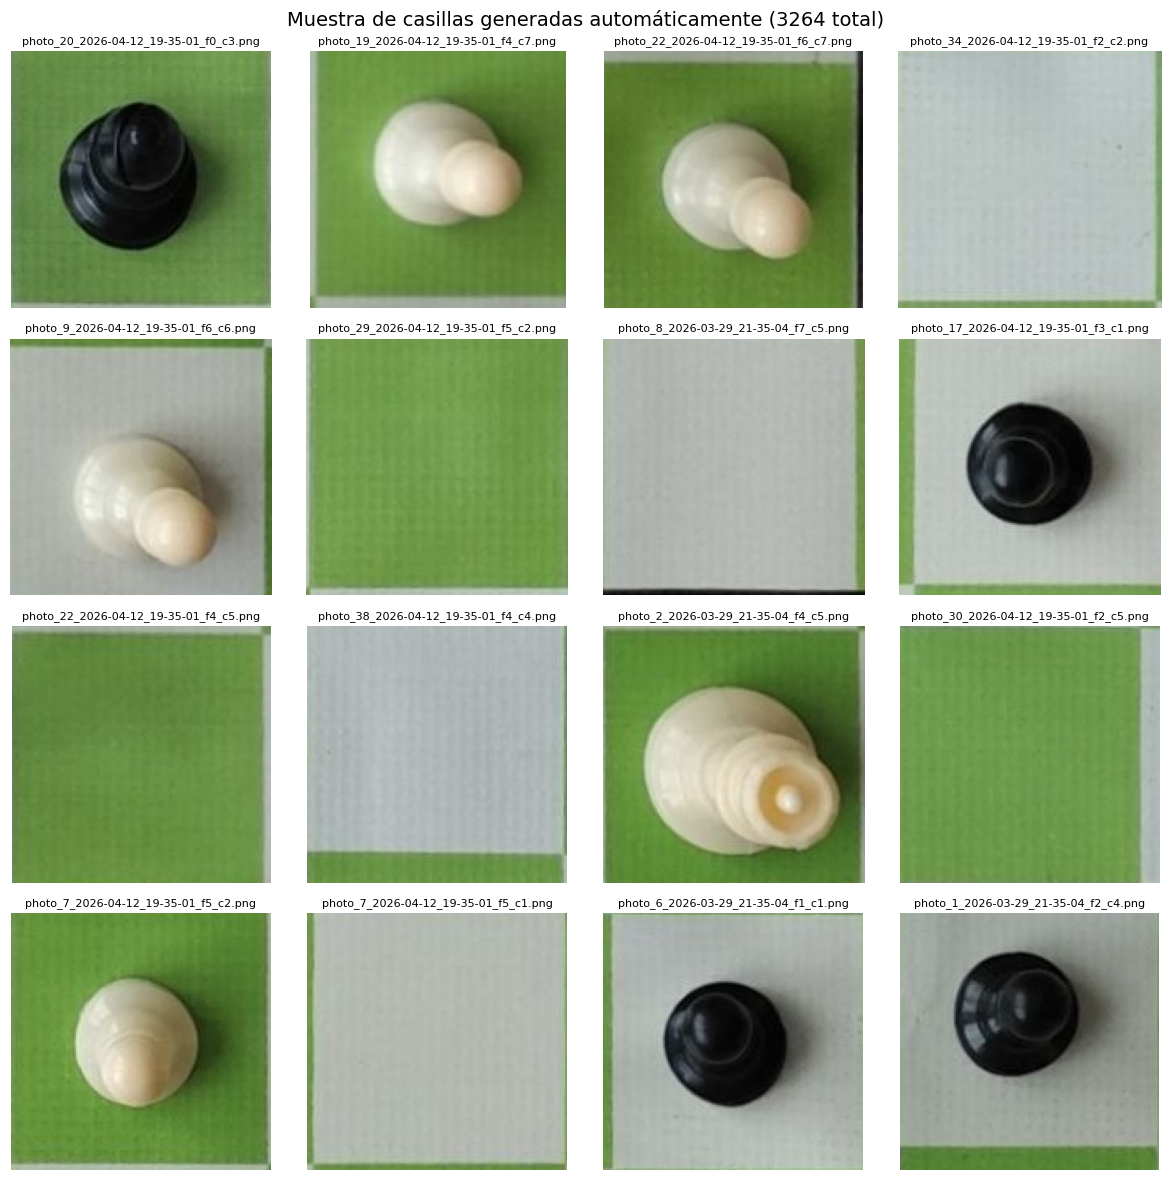


Estadísticas por imagen:
  photo_10_2026-03-29_21-35-04: 64 casillas
  photo_10_2026-04-12_19-35-01: 64 casillas
  photo_11_2026-03-29_21-35-04: 64 casillas
  photo_11_2026-04-12_19-35-01: 64 casillas
  photo_12_2026-03-29_21-35-04: 64 casillas
  photo_12_2026-04-12_19-35-01: 64 casillas
  photo_13_2026-03-29_21-35-04: 64 casillas
  photo_13_2026-04-12_19-35-01: 64 casillas
  photo_14_2026-04-12_19-35-01: 64 casillas
  photo_15_2026-04-12_19-35-01: 64 casillas
  ... y 41 imágenes más


In [9]:
# Verificar y visualizar casillas generadas
archivos_generados = [f for f in os.listdir(output_dir) if f.endswith(".png")]

if archivos_generados:
    print(f"Total de archivos generados: {len(archivos_generados)}")
    
    # Mostrar una muestra aleatoria
    n_muestra = min(16, len(archivos_generados))
    muestra = random.sample(archivos_generados, n_muestra)
    
    fig, axes = plt.subplots(4, 4, figsize=(12, 12))
    for idx, ax in enumerate(axes.flat):
        if idx < len(muestra):
            img_path = os.path.join(output_dir, muestra[idx])
            img = cv2.imread(img_path)
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            ax.imshow(img)
            ax.set_title(muestra[idx], fontsize=8)
        ax.axis('off')
    
    plt.suptitle(f'Muestra de casillas generadas automáticamente ({len(archivos_generados)} total)', fontsize=14)
    plt.tight_layout()
    plt.show()
    
    # Estadísticas por imagen
    print("\nEstadísticas por imagen:")
    imagenes_stats = {}
    for archivo in archivos_generados:
        nombre_base = archivo.split('_f')[0]
        if nombre_base not in imagenes_stats:
            imagenes_stats[nombre_base] = 0
        imagenes_stats[nombre_base] += 1
    
    for img_name, count in list(imagenes_stats.items())[:10]:  # Mostrar primeras 10
        print(f"  {img_name}: {count} casillas")
    
    if len(imagenes_stats) > 10:
        print(f"  ... y {len(imagenes_stats) - 10} imágenes más")
    
else:
    print("No se generaron casillas. Verifica que las imágenes existan en el directorio de entrada.")